# Practical 2: Email Spam Detection (KNN and SVM)

**Aim:** Classify emails as *Not Spam* (normal state, 0) or *Spam* (abnormal state, 1) using K-Nearest Neighbors and Support Vector Machine, and analyse their performance.

## Setup: libraries and dataset loader

The loader tries Kaggle first. If the download fails, it asks you to upload the CSV (a file picker appears). You can also drag the CSV into the Colab Files panel before running.

In [1]:
!pip install -q kagglehub

import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

def get_dataset(kaggle_handle, filename, fallback_url=None, fallback_kwargs=None, **read_kwargs):
    """Load a CSV. Order: (1) file already in the Colab workspace, (2) Kaggle via kagglehub,
    (3) optional public fallback URL, (4) manual upload prompt."""
    # 1. already present (e.g. you dragged it into the Colab Files panel)
    for p in [filename, f"/content/{filename}"]:
        if os.path.exists(p):
            print("Using existing file:", p)
            return pd.read_csv(p, **read_kwargs)
    # 2. Kaggle
    try:
        import kagglehub
        folder = kagglehub.dataset_download(kaggle_handle)
        hits = glob.glob(os.path.join(folder, "**", filename), recursive=True)
        if hits:
            print("Downloaded from Kaggle:", hits[0])
            return pd.read_csv(hits[0], **read_kwargs)
        print("Kaggle download worked but", filename, "was not found inside it.")
    except Exception as e:
        print("Kaggle download failed:", type(e).__name__, str(e)[:200])
    # 3. public fallback
    if fallback_url:
        try:
            print("Trying fallback URL ...")
            return pd.read_csv(fallback_url, **(fallback_kwargs or read_kwargs))
        except Exception as e:
            print("Fallback failed:", type(e).__name__)
    # 4. manual upload
    print(f"Please upload {filename} (download it from https://www.kaggle.com/datasets/{kaggle_handle})")
    from google.colab import files
    up = files.upload()
    name = next(iter(up))
    return pd.read_csv(name, **read_kwargs)

print("Setup complete")

Setup complete


In [2]:
from sklearn.model_selection import train_test_split

In [3]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

df2 = get_dataset("balaka18/email-spam-classification-dataset-csv", "emails.csv")
print(df2.shape)
print(df2["Prediction"].value_counts())   # 0 = Not Spam, 1 = Spam
print("Missing values:", df2.isnull().sum().sum())

100%|██████████| 1.66M/1.66M [00:01<00:00, 1.66MB/s]

Extracting files...


Downloaded from Kaggle: /root/.cache/kagglehub/datasets/balaka18/email-spam-classification-dataset-csv/versions/1/emails.csv
(5172, 3002)
Prediction
0    3672
1    1500
Name: count, dtype: int64
Missing values: 0


In [4]:
X2 = df2.drop(columns=["Email No.", "Prediction"])
y2 = df2["Prediction"]
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=0.2, random_state=42, stratify=y2)

knn = KNeighborsClassifier(n_neighbors=5).fit(X2_train, y2_train)
knn_pred = knn.predict(X2_test)

svm = SVC(kernel="linear", C=1.0).fit(X2_train, y2_train)
svm_pred = svm.predict(X2_test)
print("KNN and SVM trained")

KNN and SVM trained



===== KNN (k=5) =====
Confusion Matrix:
 [[648  87]
 [ 46 254]]
              precision    recall  f1-score   support

    Not Spam       0.93      0.88      0.91       735
        Spam       0.74      0.85      0.79       300

    accuracy                           0.87      1035
   macro avg       0.84      0.86      0.85      1035
weighted avg       0.88      0.87      0.87      1035


===== SVM (linear) =====
Confusion Matrix:
 [[716  19]
 [ 15 285]]
              precision    recall  f1-score   support

    Not Spam       0.98      0.97      0.98       735
        Spam       0.94      0.95      0.94       300

    accuracy                           0.97      1035
   macro avg       0.96      0.96      0.96      1035
weighted avg       0.97      0.97      0.97      1035



,Model,Accuracy,Precision,Recall,F1-Score
0,KNN (k=5),0.8715,0.7449,0.8467,0.7925
1,SVM (linear),0.9671,0.9375,0.9500,0.9437


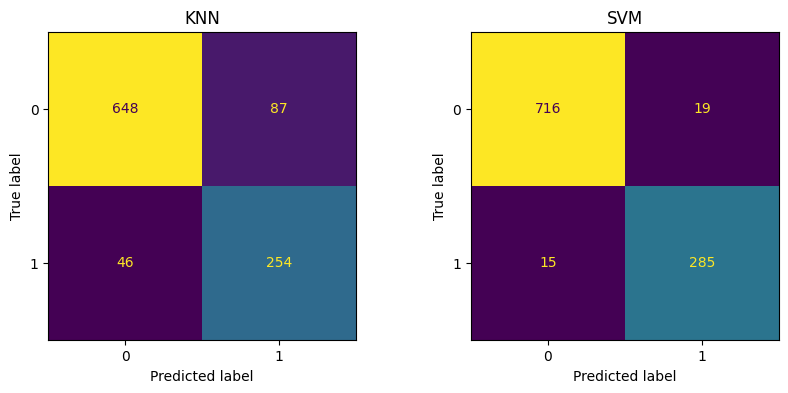

In [5]:
def report(name, y_true, y_pred):
    print(f"\n===== {name} =====")
    print("Confusion Matrix:\n", confusion_matrix(y_true, y_pred))
    print(classification_report(y_true, y_pred, target_names=["Not Spam", "Spam"]))
    return {"Model": name, "Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred),
            "Recall": recall_score(y_true, y_pred), "F1-Score": f1_score(y_true, y_pred)}

results2 = pd.DataFrame([report("KNN (k=5)", y2_test, knn_pred),
                         report("SVM (linear)", y2_test, svm_pred)]).round(4)
display(results2)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y2_test, knn_pred, ax=ax[0], colorbar=False); ax[0].set_title("KNN")
ConfusionMatrixDisplay.from_predictions(y2_test, svm_pred, ax=ax[1], colorbar=False); ax[1].set_title("SVM")
plt.show()

### Effect of K on KNN accuracy

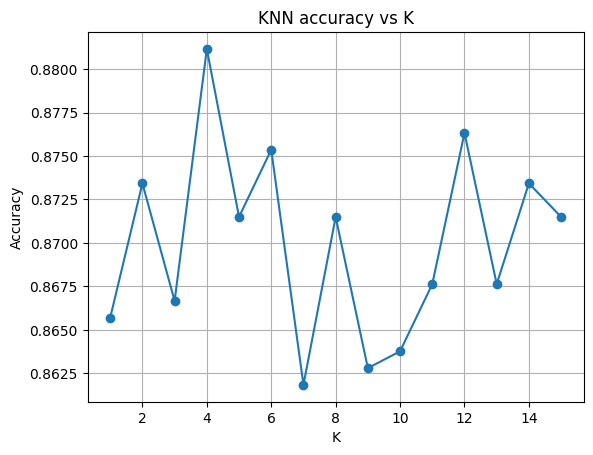

In [6]:
ks = range(1, 16)
acc = [accuracy_score(y2_test, KNeighborsClassifier(n_neighbors=k).fit(X2_train, y2_train).predict(X2_test)) for k in ks]
plt.plot(ks, acc, marker="o"); plt.xlabel("K"); plt.ylabel("Accuracy")
plt.title("KNN accuracy vs K"); plt.grid(True); plt.show()

**Conclusion (Practical 2):** Compare the two rows in the results table. SVM usually handles the 3000-dimensional word-count data better than KNN and predicts faster.